# Week 7-C3: Anchor-and-Deviate Semantic Budget Policy

## Section 0 — Research Question & Motivation
In Week 7-C1, the sufficiency-classification policy failed due to catastrophic large-$k$ fallback behavior ($F_1 = 0.3783$, context $\approx 1503.8$).
In Week 7-C2, direct response-surface regression and ranking recovered quality ($F_1 = 0.3922$) but massively over-allocated ($k=7.39$, tokens $\approx 1622.1$, dominated by static $k=6$ and $k=8$).

Error taxonomy analysis revealed that **$63.6\%$ of queries were epsilon-admissible but over-budget**, and **$26.8\%$ selected higher budgets that degraded quality** (non-monotonicity).

### The Week 7-C3 Paradigm Shift: Anchor-and-Deviate
Static semantic $k=4$ is exceptionally strong:
$$F_1 = 0.3909 \quad \text{at only } 921.1 \text{ context tokens}.$$

Instead of predicting across all budgets symmetrically, Week 7-C3 treats **$k=4$ as the default deployment anchor** and asks two asymmetric questions:
1. **SAFE DOWNSHIFT:** Can this query safely use $k=2$ instead of $k=4$? ($P_{down} \ge \tau_{down}$)
2. **SELECTIVE UPSHIFT:** Does this query gain enough downstream quality from $k > 4$ to justify leaving $k=4$? ($P_{up} \ge \tau_{up}$)
3. **ANCHOR PRESERVATION:** If neither condition is confidently satisfied, retain default **$k=4$**!

This experiment strictly avoids any $k=8$ fallback assumption.


In [1]:
# Setup environment and imports
import os
import sys
import json
import yaml
from pathlib import Path
from typing import Dict, List, Any, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve Project Root across execution environments
_curr = Path.cwd().resolve()
candidates = [_curr, _curr.parent, _curr.parent.parent]
PROJECT_ROOT = next((p for p in candidates if (p / "src").is_dir() and (p / "configs").is_dir()), _curr)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

from src.week7.w7c3.data import (
    ALLOWED_BUDGETS,
    ANCHOR_K,
    assert_test_disabled,
    assert_zero_feature_leakage,
    build_w7c3_query_dataset,
    get_feature_subsets,
    load_w7c3_splits,
)
from src.week7.w7c3.targets import (
    compute_oracle_admissible_set,
    compute_minimum_cost_oracle_k,
    compute_safe_downshift_target,
    compute_selective_upshift_target,
    compute_delta_regression_targets,
    compute_4to6_gain_target,
)
from src.week7.w7c3.downshift import SafeDownshiftClassifier
from src.week7.w7c3.upshift import SelectiveUpshiftClassifier
from src.week7.w7c3.delta_models import MarginalGainDeltaRegressors
from src.week7.w7c3.oof import run_group_kfold_oof, evaluate_oof_policy_grid
from src.week7.w7c3.policy import (
    apply_anchor_deviate_decision_rule,
    evaluate_downstream_anchor_policy,
    select_best_anchor_policy,
)
from src.week7.w7c3.evaluation import (
    compute_w7c3_error_taxonomy,
    compute_downshift_safety_metrics,
    compute_upshift_precision_metrics,
    compute_recovered_oracle_headroom,
    run_paper_clustered_bootstrap,
)
from src.week7.w7c3.diagnostics import (
    compute_anchor_oracle_diagnostics,
    compute_4to6_gain_analysis,
)

# Load configuration
CONFIG_PATH = PROJECT_ROOT / "configs/week7/w7c3_anchor_deviate.yaml"
with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

# Validate that TEST split access is strictly blocked
try:
    assert_test_disabled("test")
except RuntimeError as e:
    print(f"PASS: TEST split access guard strictly validated: {e}")

print(f"Config loaded: anchor_k={cfg['experiment']['anchor_k']}, budgets={cfg['experiment']['budgets']}")


PASS: TEST split access guard strictly validated: TEST split access is strictly prohibited in Week 7-C3! TEST must remain untouched.
Config loaded: anchor_k=4, budgets=[2, 4, 5, 6, 8]


## Section 1 — Load Canonical Response Surfaces
We load the canonical fixed-$k$ semantic response surfaces for TRAIN ($2,088$ queries) and DEV ($231$ queries).
No SARA inference regeneration is required; all evaluations lookup exact ground-truth values.


In [2]:
# Load canonical response surfaces
df_train_matrix = pd.read_csv(PROJECT_ROOT / cfg["paths"]["train_response_matrix"])
df_dev_matrix = pd.read_csv(PROJECT_ROOT / cfg["paths"]["dev_response_matrix"])

df_train_matrix["question_id"] = df_train_matrix["question_id"].astype(str).str.strip()
df_dev_matrix["question_id"] = df_dev_matrix["question_id"].astype(str).str.strip()
df_train_matrix["paper_id"] = df_train_matrix["paper_id"].astype(str).str.strip()
df_dev_matrix["paper_id"] = df_dev_matrix["paper_id"].astype(str).str.strip()

print(f"TRAIN response surface: {len(df_train_matrix)} queries across {df_train_matrix['paper_id'].nunique()} papers")
print(f"DEV response surface:   {len(df_dev_matrix)} queries across {df_dev_matrix['paper_id'].nunique()} papers")

# Assert disjoint split
assert set(df_train_matrix["question_id"]).isdisjoint(set(df_dev_matrix["question_id"])), "LEAKAGE: Overlapping query IDs!"
assert set(df_train_matrix["paper_id"]).isdisjoint(set(df_dev_matrix["paper_id"])), "LEAKAGE: Overlapping paper IDs!"
print("PASS: Zero leakage verified between TRAIN and DEV.")


TRAIN response surface: 2088 queries across 772 papers
DEV response surface:   231 queries across 86 papers
PASS: Zero leakage verified between TRAIN and DEV.


## Section 2 — Oracle Anchor Diagnostics
We analyze the oracle behavior on TRAIN:
- $P(k2 \in \mathcal{A}_\epsilon)$: Potential for safe downshifting.
- $P(k4 \in \mathcal{A}_\epsilon)$: Quality preservation rate of the default anchor.
- $P(k4 \notin \mathcal{A}_\epsilon)$: Frequency where $k=4$ is inadequate.
- Distribution of cheapest admissible larger budget when $k=4$ is inadequate.
- $P(k8 \notin \mathcal{A}_\epsilon)$: Inadmissibility rate of $k=8$, proving why fallback to $k=8$ fails.


In [3]:
# Compute Oracle Anchor Diagnostics on TRAIN
oracle_stats, df_anchor_diag = compute_anchor_oracle_diagnostics(
    response_matrix_df=df_train_matrix,
    budgets=cfg["experiment"]["budgets"],
    anchor_k=cfg["experiment"]["anchor_k"],
    epsilon=cfg["experiment"]["epsilon"],
)

tables_dir = PROJECT_ROOT / cfg["paths"]["tables_dir"]
tables_dir.mkdir(parents=True, exist_ok=True)
df_anchor_diag.to_csv(tables_dir / "w7c3_anchor_oracle_diagnostics.csv", index=False)

print("Oracle Anchor Diagnostics on TRAIN (N=2088):")
display(df_anchor_diag)
print(f"  k=2 Admissible: {oracle_stats['k2_admissible_rate']*100:.1f}%")
print(f"  k=4 Admissible: {oracle_stats['k4_admissible_rate']*100:.1f}%")
print(f"  k=4 Inadequate: {oracle_stats['k4_inadequate_rate']*100:.1f}%")
print(f"  k=8 INADMISSIBLE: {oracle_stats['k8_inadmissible_rate']*100:.1f}% (Proof that k=8 fallback fails!)")
print(f"  Cheapest larger budget among k4-inadequate: {oracle_stats['cheapest_larger_counts']}")


Oracle Anchor Diagnostics on TRAIN (N=2088):


,metric,value,count,description
0,k2_admissible_rate,0.607759,1269,Queries where k=2 preserves quality (safe down...
1,k4_admissible_rate,0.676245,1412,Queries where anchor k=4 is epsilon-admissible
2,k4_inadequate_rate,0.323755,676,Queries where anchor k=4 misses oracle by > ep...
3,k8_inadmissible_rate,0.252395,527,Queries where k=8 is NOT admissible (proof of ...
4,k4_inadeq_cheapest_k5,0.276627,187,"Among k4-inadequate queries, fraction where k5..."
5,k4_inadeq_cheapest_k6,0.214497,145,"Among k4-inadequate queries, fraction where k6..."
6,k4_inadeq_cheapest_k8,0.276627,187,"Among k4-inadequate queries, fraction where k8..."
7,k4_inadeq_cheapest_none,0.232249,157,"Among k4-inadequate queries, fraction where no..."


  k=2 Admissible: 60.8%
  k=4 Admissible: 67.6%
  k=4 Inadequate: 32.4%
  k=8 INADMISSIBLE: 25.2% (Proof that k=8 fallback fails!)
  Cheapest larger budget among k4-inadequate: {'k5': 187, 'k6': 145, 'k8': 187, 'none': 157}


## Section 3 — 4->6 Gain Analysis ($G_{4\to 6}$)
We examine the distribution of $G_{4\to 6} = F(q, 6) - F(q, 4)$. This feeds the multi-fidelity compression design for Week 7-D.


4->6 Marginal Gain Analysis on TRAIN:


,metric,value,description
0,mean_gain,0.023367,Mean downstream F1 gain from adding passages 5...
1,median_gain,0.000000,Median gain (typically 0.0)
2,std_gain,0.220017,Standard deviation of 4->6 gains
3,positive_fraction,0.177682,Fraction of queries with strictly positive gain
4,gain_gt_0_01,0.173372,Fraction with meaningful quality improvement (...
5,loss_lt_minus_0_01,0.117816,Fraction with meaningful quality degradation (...
6,zero_fraction,0.700192,Fraction of queries where adding passages 5 an...


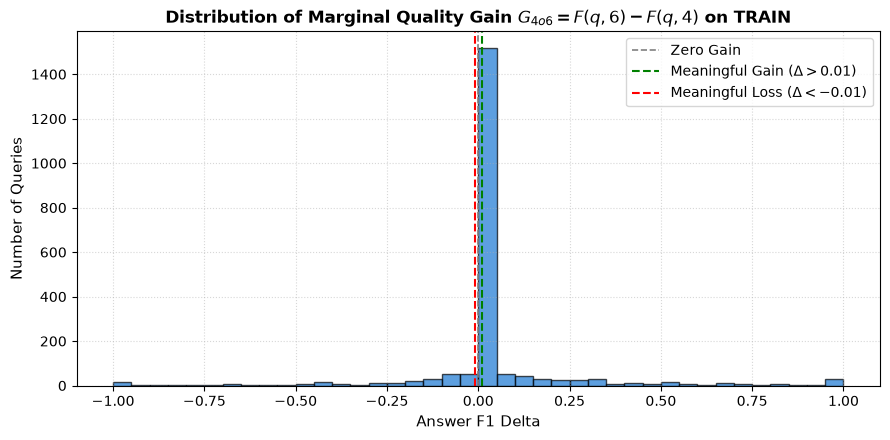

In [4]:
# Compute 4->6 marginal gain distribution
gain_stats, df_46_table = compute_4to6_gain_analysis(
    response_matrix_df=df_train_matrix,
    anchor_k=cfg["experiment"]["anchor_k"],
    epsilon=cfg["experiment"]["epsilon"],
)

df_46_table.to_csv(tables_dir / "w7c3_4_to_6_gain_analysis.csv", index=False)
print("4->6 Marginal Gain Analysis on TRAIN:")
display(df_46_table)

# Plot distribution of 4->6 gains
fig_dir = PROJECT_ROOT / cfg["paths"]["figures_dir"]
fig_dir.mkdir(parents=True, exist_ok=True)

g_46 = df_train_matrix["f1_k6"] - df_train_matrix["f1_k4"]

plt.figure(figsize=(9, 4.5))
plt.hist(g_46, bins=40, color="#1976D2", edgecolor="black", alpha=0.7)
plt.axvline(0.0, color="gray", linestyle="--", linewidth=1.2, label="Zero Gain")
plt.axvline(0.01, color="green", linestyle="--", linewidth=1.5, label=r"Meaningful Gain ($\Delta > 0.01$)")
plt.axvline(-0.01, color="red", linestyle="--", linewidth=1.5, label=r"Meaningful Loss ($\Delta < -0.01$)")
plt.title(r"Distribution of Marginal Quality Gain $G_{4 	o 6} = F(q, 6) - F(q, 4)$ on TRAIN", fontsize=12, fontweight="bold")
plt.xlabel("Answer F1 Delta", fontsize=11)
plt.ylabel("Number of Queries", fontsize=11)
plt.legend(frameon=True)
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.savefig(fig_dir / "w7c3_4_to_6_gain_distribution.png", dpi=300)
plt.show()


## Section 4 — Load Feature Bank & Build Datasets
We load the precomputed retrieval-aware candidate feature bank from Week 7-C and construct clean, leak-free per-query representations for TRAIN and DEV.


In [5]:
# Load candidate features parquet files
df_train_cand_raw = pd.read_parquet(PROJECT_ROOT / cfg["paths"]["train_candidate_features"])
df_dev_cand_raw = pd.read_parquet(PROJECT_ROOT / cfg["paths"]["dev_candidate_features"])

print(f"Raw candidate feature rows: TRAIN={len(df_train_cand_raw)}, DEV={len(df_dev_cand_raw)}")

# Build unified query datasets
df_train_query = build_w7c3_query_dataset(
    candidate_features_df=df_train_cand_raw,
    response_matrix_df=df_train_matrix,
    budgets=cfg["experiment"]["budgets"],
    anchor_k=cfg["experiment"]["anchor_k"],
    epsilon=cfg["experiment"]["epsilon"],
    split_name="train",
)

df_dev_query = build_w7c3_query_dataset(
    candidate_features_df=df_dev_cand_raw,
    response_matrix_df=df_dev_matrix,
    budgets=cfg["experiment"]["budgets"],
    anchor_k=cfg["experiment"]["anchor_k"],
    epsilon=cfg["experiment"]["epsilon"],
    split_name="dev",
)

downshift_feats, upshift_feats, delta_feats = get_feature_subsets(df_train_query)
print(f"Dataset assembled:")
print(f"  TRAIN Queries: {len(df_train_query)} across {df_train_query['paper_id'].nunique()} papers")
print(f"  DEV Queries:   {len(df_dev_query)} across {df_dev_query['paper_id'].nunique()} papers")
print(f"  Feature subsets: Downshift={len(downshift_feats)}, Upshift={len(upshift_feats)}, Delta={len(delta_feats)}")


Raw candidate feature rows: TRAIN=10440, DEV=1155
Dataset assembled:
  TRAIN Queries: 2088 across 772 papers
  DEV Queries:   231 across 86 papers
  Feature subsets: Downshift=153, Upshift=111, Delta=111


## Section 5 to 7 — Target Distribution Statistics
We verify the supervisory label rates on TRAIN:
- Downshift target $y_{down}(q)$: $60.8\%$ positive rate.
- Upshift target $y_{up}(q)$: $27.0\%$ positive rate.
- Marginal gain deltas: $\Delta_5, \Delta_6, \Delta_8$ relative to anchor $k=4$.


In [6]:
# Target diagnostics
down_stats_rows = [{
    "target": "target_y_down",
    "positive_rate": float(df_train_query["target_y_down"].mean()),
    "positive_count": int(df_train_query["target_y_down"].sum()),
    "total_queries": len(df_train_query),
}]
df_down_stats = pd.DataFrame(down_stats_rows)
df_down_stats.to_csv(tables_dir / "w7c3_downshift_target_stats.csv", index=False)

up_stats_rows = [
    {
        "target": "target_y_up",
        "positive_rate": float(df_train_query["target_y_up"].mean()),
        "positive_count": int(df_train_query["target_y_up"].sum()),
        "total_queries": len(df_train_query),
    },
    {
        "target": "target_delta_5_mean",
        "positive_rate": float(np.mean(df_train_query["target_delta_5"] > 0)),
        "positive_count": int(np.sum(df_train_query["target_delta_5"] > 0)),
        "total_queries": len(df_train_query),
    },
    {
        "target": "target_delta_6_mean",
        "positive_rate": float(np.mean(df_train_query["target_delta_6"] > 0)),
        "positive_count": int(np.sum(df_train_query["target_delta_6"] > 0)),
        "total_queries": len(df_train_query),
    },
    {
        "target": "target_delta_8_mean",
        "positive_rate": float(np.mean(df_train_query["target_delta_8"] > 0)),
        "positive_count": int(np.sum(df_train_query["target_delta_8"] > 0)),
        "total_queries": len(df_train_query),
    },
]
df_up_stats = pd.DataFrame(up_stats_rows)
df_up_stats.to_csv(tables_dir / "w7c3_upshift_target_stats.csv", index=False)

print("Downshift Target Stats:")
display(df_down_stats)
print("Upshift & Delta Target Stats:")
display(df_up_stats)


Downshift Target Stats:


,target,positive_rate,positive_count,total_queries
0,target_y_down,0.607759,1269,2088


Upshift & Delta Target Stats:


,target,positive_rate,positive_count,total_queries
0,target_y_up,0.269636,563,2088
1,target_delta_5_mean,0.135536,283,2088
2,target_delta_6_mean,0.177682,371,2088
3,target_delta_8_mean,0.223180,466,2088


## Section 8 to 11 — 5-Fold GroupKFold OOF Training
We run paper-disjoint 5-fold cross-validation on all $2,088$ TRAIN queries:
1. `SafeDownshiftClassifier` (D1) estimates $P_{down}(q)$.
2. `SelectiveUpshiftClassifier` (U1) estimates $P_{up}(q)$.
3. `MarginalGainDeltaRegressors` (U2) estimates $(\hat{\Delta}_5, \hat{\Delta}_6, \hat{\Delta}_8)$.
Every query receives out-of-fold predictions without leakage.


In [7]:
# Run 5-fold GroupKFold OOF estimation
print("Executing 5-fold GroupKFold OOF cross-validation...")
df_oof = run_group_kfold_oof(
    df_train_query=df_train_query,
    downshift_features=downshift_feats,
    upshift_features=upshift_feats,
    delta_features=delta_feats,
    n_splits=cfg["group_k_fold"]["n_splits"],
    group_col=cfg["group_k_fold"]["group_column"],
    model_params=cfg["model_hyperparameters"],
)

oof_dir = PROJECT_ROOT / cfg["paths"]["oof_dir"]
oof_dir.mkdir(parents=True, exist_ok=True)
df_oof.to_parquet(oof_dir / "w7c3_oof_predictions.parquet", index=False)

print(f"OOF generation complete. Shape: {df_oof.shape}")
print("OOF Prediction Summary:")
display(df_oof[["p_down", "p_up", "pred_delta_5", "pred_delta_6", "pred_delta_8"]].describe())


Executing 5-fold GroupKFold OOF cross-validation...
OOF generation complete. Shape: (2088, 8)
OOF Prediction Summary:


,p_down,p_up,pred_delta_5,pred_delta_6,pred_delta_8
count,2088.000000,2088.000000,2088.000000,2088.000000,2088.000000
mean,0.611989,0.266505,0.012111,0.023528,0.043789
std,0.151600,0.125977,0.034432,0.040418,0.048331
min,0.140102,0.017567,-0.178161,-0.108876,-0.132154
25%,0.513905,0.195327,-0.006367,0.000752,0.013378
50%,0.587404,0.280906,0.011617,0.022546,0.040914
75%,0.691417,0.348486,0.029641,0.044467,0.069836
max,0.963339,0.751503,0.167377,0.221308,0.234795


## Section 12 to 14 — OOF Policy Grid Evaluation & Quality-Constrained Selection
We evaluate policy threshold combinations:
- $\tau_{down} \in [0.70, 0.75, 0.80, 0.85, 0.90, 0.95]$
- $\tau_{up} \in [0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85]$
- $\delta_{up} \in [0.0, 0.005, 0.01, 0.02]$

### Quality-Constrained Cost Minimization Selection Rule:
1. Reference: OOF static semantic $k=4$ performance ($F1_{k4, OOF}$).
2. Allowable degradation: $\eta = 0.005$.
3. Filter qualifying policies: $F1_{policy} \ge F1_{k4, OOF} - \eta$.
4. Among qualifying policies, select the one with **LOWEST mean context tokens**.
5. Tie-break: lower under-allocation rate, then simpler thresholds.


In [8]:
# Evaluate policy grid over OOF predictions
print("Evaluating OOF policy grid...")
df_grid = evaluate_oof_policy_grid(
    df_oof=df_oof,
    df_response_matrix=df_train_matrix,
    tau_down_grid=cfg["policy_grids"]["tau_down_grid"],
    tau_up_grid=cfg["policy_grids"]["tau_up_grid"],
    delta_up_grid=cfg["policy_grids"]["delta_up_grid"],
    anchor_k=cfg["experiment"]["anchor_k"],
    budgets=cfg["experiment"]["budgets"],
    epsilon=cfg["experiment"]["epsilon"],
)

df_grid.to_csv(tables_dir / "w7c3_oof_policy_grid.csv", index=False)

# Compute OOF static k4 reference
f1_k4_oof_ref = float(df_train_matrix["f1_k4"].mean())
tokens_k4_oof_ref = float(df_train_matrix["tokens_k4"].mean())
print(f"OOF Static k=4 Reference: F1={f1_k4_oof_ref:.4f}, Tokens={tokens_k4_oof_ref:.1f}")

# Quality-constrained cost minimization selection
eta = cfg["experiment"]["quality_tolerance_eta"]
winner_policy, df_grid_annotated = select_best_anchor_policy(
    df_grid=df_grid,
    f1_k4_reference=f1_k4_oof_ref,
    eta=eta,
)

df_winner = pd.DataFrame([winner_policy])
df_winner.to_csv(tables_dir / "w7c3_policy_selection.csv", index=False)

print(f"\nWINNING POLICY SELECTED (Status: {winner_policy['selection_status']}):")
print(f"  tau_down = {winner_policy['tau_down']:.2f}")
print(f"  tau_up   = {winner_policy['tau_up']:.2f}")
print(f"  delta_up = {winner_policy['delta_up']:.4f}")
print(f"  OOF F1   = {winner_policy['mean_f1']:.4f} (Delta vs k4: {winner_policy['mean_f1'] - f1_k4_oof_ref:+.4f})")
print(f"  OOF Toks = {winner_policy['mean_tokens']:.1f} (Saved vs k4: {tokens_k4_oof_ref - winner_policy['mean_tokens']:+.1f} tokens)")
print(f"  Mean k   = {winner_policy['mean_k']:.2f}")


Evaluating OOF policy grid...
OOF Static k=4 Reference: F1=0.3862, Tokens=931.7

WINNING POLICY SELECTED (Status: QUALIFIED_LOWEST_TOKENS):
  tau_down = 0.90
  tau_up   = 0.85
  delta_up = 0.0000
  OOF F1   = 0.3846 (Delta vs k4: -0.0015)
  OOF Toks = 909.0 (Saved vs k4: +22.6 tokens)
  Mean k   = 3.89


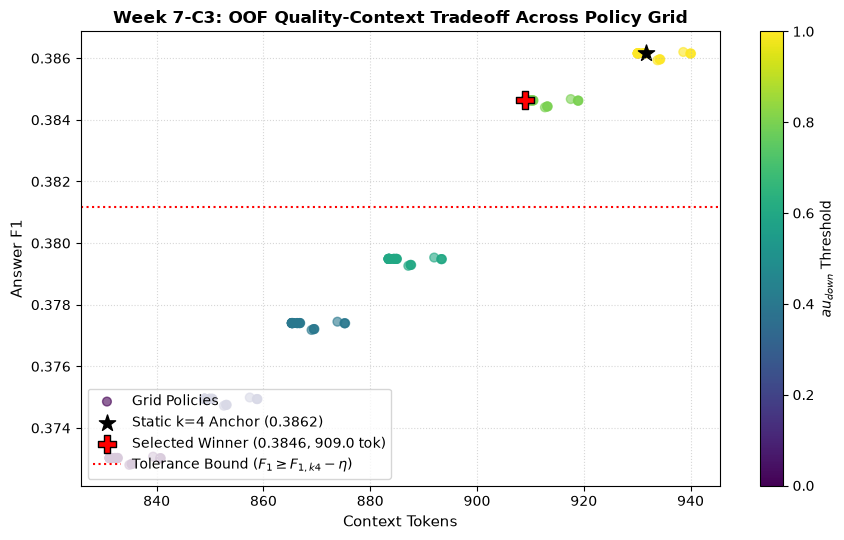

In [9]:
# Plot OOF Quality vs Tokens Frontier across Policy Grid
plt.figure(figsize=(9, 5.5))
plt.scatter(df_grid["mean_tokens"], df_grid["mean_f1"], c=df_grid["tau_down"], cmap="viridis", alpha=0.6, s=40, label="Grid Policies")
plt.scatter([tokens_k4_oof_ref], [f1_k4_oof_ref], color="black", s=150, marker="*", label=f"Static k=4 Anchor ({f1_k4_oof_ref:.4f})")
plt.scatter([winner_policy["mean_tokens"]], [winner_policy["mean_f1"]], color="red", s=180, marker="P", edgecolor="black", label=f"Selected Winner ({winner_policy['mean_f1']:.4f}, {winner_policy['mean_tokens']:.1f} tok)")

plt.axhline(f1_k4_oof_ref - eta, color="red", linestyle=":", label=r"Tolerance Bound ($F_1 \geq F_{1,k4} - \eta$)")
plt.colorbar(label=r"$	au_{down}$ Threshold")
plt.title(r"Week 7-C3: OOF Quality-Context Tradeoff Across Policy Grid", fontsize=12, fontweight="bold")
plt.xlabel("Context Tokens", fontsize=11)
plt.ylabel("Answer F1", fontsize=11)
plt.legend(frameon=True, loc="lower left")
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.savefig(fig_dir / "w7c3_oof_quality_vs_tokens.png", dpi=300)
plt.show()


## Section 15 & 16 — Full TRAIN Retraining & Frozen DEV Evaluation
The policy thresholds $(\tau_{down}^*, \tau_{up}^*, \delta_{up}^*)$ are now frozen.
We retrain D1, U1, and delta regressors on ALL $2,088$ TRAIN queries, and evaluate DEV ($231$ queries) **ONCE**.


In [10]:
# Retrain final models on full TRAIN
print("Retraining final models on ALL TRAIN queries...")
final_down_clf = SafeDownshiftClassifier(**cfg["model_hyperparameters"]["downshift_classifier"])
final_down_clf.fit(df_train_query[downshift_feats], df_train_query["target_y_down"])

final_up_clf = SelectiveUpshiftClassifier(**cfg["model_hyperparameters"]["upshift_classifier"])
final_up_clf.fit(df_train_query[upshift_feats], df_train_query["target_y_up"])

final_delta_regs = MarginalGainDeltaRegressors(**cfg["model_hyperparameters"]["delta_regressors"])
final_delta_regs.fit(df_train_query[delta_feats], df_train_query)

# Evaluate on DEV once
print("Applying frozen policy to DEV (231 queries)...")
p_down_dev = final_down_clf.predict_proba(df_dev_query[downshift_feats])
p_up_dev = final_up_clf.predict_proba(df_dev_query[upshift_feats])
pred_deltas_dev = final_delta_regs.predict_deltas(df_dev_query[delta_feats])

dev_chosen_ks = {}
for i, (_, row) in enumerate(df_dev_query.iterrows()):
    qid = str(row["question_id"]).strip()
    deltas_q = {5: float(pred_deltas_dev[5][i]), 6: float(pred_deltas_dev[6][i]), 8: float(pred_deltas_dev[8][i])}
    k_choice = apply_anchor_deviate_decision_rule(
        p_down=float(p_down_dev[i]),
        p_up=float(p_up_dev[i]),
        pred_deltas=deltas_q,
        tau_down=winner_policy["tau_down"],
        tau_up=winner_policy["tau_up"],
        delta_up=winner_policy["delta_up"],
        anchor_k=cfg["experiment"]["anchor_k"],
    )
    dev_chosen_ks[qid] = k_choice

df_dev_eval = df_dev_matrix.copy()
df_dev_eval["pred_k"] = [dev_chosen_ks[q] for q in df_dev_eval["question_id"]]

dev_policy_metrics = evaluate_downstream_anchor_policy(
    predicted_ks=dev_chosen_ks,
    response_matrix_df=df_dev_matrix,
    budgets=cfg["experiment"]["budgets"],
    anchor_k=cfg["experiment"]["anchor_k"],
    epsilon=cfg["experiment"]["epsilon"],
)

print("\nFROZEN DEV EVALUATION RESULTS:")
print(f"  Mean Answer F1:   {dev_policy_metrics['mean_f1']:.4f}")
print(f"  Context Tokens:   {dev_policy_metrics['mean_tokens']:.1f}")
print(f"  Mean Budget k:    {dev_policy_metrics['mean_k']:.2f}")
print(f"  ROH_sem:          {dev_policy_metrics['ROH_sem']:.4f}")
print(f"  Admissible Rate:  {dev_policy_metrics['admissible_rate']*100:.1f}%")
print(f"  Exact Oracle:     {dev_policy_metrics['exact_oracle_rate']*100:.1f}%")
print(f"  Anchor Rate (k4): {dev_policy_metrics['anchor_rate']*100:.1f}%")
print(f"  Downshift (k2):   {dev_policy_metrics['downshift_rate']*100:.1f}%")
print(f"  Upshift (>4):     {dev_policy_metrics['upshift_rate']*100:.1f}%")


Retraining final models on ALL TRAIN queries...
Applying frozen policy to DEV (231 queries)...

FROZEN DEV EVALUATION RESULTS:
  Mean Answer F1:   0.3801
  Context Tokens:   903.1
  Mean Budget k:    3.90
  ROH_sem:          -0.2435
  Admissible Rate:  68.4%
  Exact Oracle:     20.3%
  Anchor Rate (k4): 95.2%
  Downshift (k2):   4.8%
  Upshift (>4):     0.0%


## Section 17 & 18 — Downshift Safety & Upshift Precision Analysis
We examine:
1. **Downshift Safety:** Did downshifting to $k=2$ actually preserve quality?
2. **Upshift Precision:** Were upward escalations justified by $> 0.01$ gains?


In [11]:
# Compute safety and precision metrics on DEV
down_safety = compute_downshift_safety_metrics(
    df_eval_queries=df_dev_eval,
    budgets=cfg["experiment"]["budgets"],
    anchor_k=cfg["experiment"]["anchor_k"],
    epsilon=cfg["experiment"]["epsilon"],
)
df_down_safety = pd.DataFrame([down_safety])
df_down_safety.to_csv(tables_dir / "w7c3_downshift_safety.csv", index=False)

up_prec = compute_upshift_precision_metrics(
    df_eval_queries=df_dev_eval,
    anchor_k=cfg["experiment"]["anchor_k"],
    epsilon=cfg["experiment"]["epsilon"],
)
df_up_prec = pd.DataFrame([up_prec])
df_up_prec.to_csv(tables_dir / "w7c3_upshift_precision.csv", index=False)

print("Downshift Safety on DEV:")
display(df_down_safety)

print("Upshift Precision on DEV:")
display(df_up_prec)


Downshift Safety on DEV:


,n_downshifted,downshift_rate_pct,precision_k2_admissible,recall_k2_admissible,mean_f1_at_k2,mean_regret_vs_oracle,mean_regret_vs_k4,mean_tokens_saved_vs_k4
0,11,4.761905,0.636364,0.05036,0.545455,0.318182,0.227273,377.0


Upshift Precision on DEV:


,n_upshifted,upshift_rate_pct,fraction_gain_gt_epsilon,mean_actual_gain_vs_k4,mean_tokens_added_vs_k4,gain_per_100_added_tokens,chosen_k_distribution
0,0,0.0,0.0,0.0,0.0,0.0,{}


## Section 19 — Extended Error Taxonomy (E1 to E6)
- **E1:** Minimum-cost oracle exactly
- **E2:** Epsilon-admissible but over-budget
- **E3:** Under-budget and inadmissible
- **E4:** Higher-budget and STILL inadmissible (negative return on context)
- **E5:** Anchor $k=4$ chosen and admissible
- **E6:** Anchor $k=4$ chosen but inadmissible


In [12]:
# Compute extended error taxonomy on DEV
df_dev_detailed, df_error_tax = compute_w7c3_error_taxonomy(
    df_eval_queries=df_dev_eval,
    budgets=cfg["experiment"]["budgets"],
    anchor_k=cfg["experiment"]["anchor_k"],
    epsilon=cfg["experiment"]["epsilon"],
)

df_error_tax.to_csv(tables_dir / "w7c3_error_taxonomy.csv", index=False)
print("Extended Error Taxonomy on DEV:")
display(df_error_tax)

# Predicted budget distribution
k_counts = df_dev_eval["pred_k"].value_counts().sort_index()
df_k_dist = pd.DataFrame({
    "budget_k": k_counts.index,
    "count": k_counts.values,
    "percentage": (k_counts.values / len(df_dev_eval)) * 100.0,
})
df_k_dist.to_csv(tables_dir / "w7c3_predicted_k_distribution.csv", index=False)
print("Predicted Budget Distribution on DEV:")
display(df_k_dist)


Extended Error Taxonomy on DEV:


,category,count,pct_queries,mean_f1_regret,mean_token_penalty
0,E1: Minimum-cost oracle exactly,47,20.346320,0.000132,0.000000
1,E2: Admissible but over-budget,111,48.051948,0.000000,410.918919
2,E3: Under-budget & inadmissible,52,22.510823,0.398293,-481.961538
3,E4: Higher-budget & STILL inadmissible,21,9.090909,0.189582,428.380952
4,E5: Anchor k=4 chosen & admissible,151,65.367965,0.000041,302.066225
5,E6: Anchor k=4 chosen & inadmissible,69,29.870130,0.307137,-206.246377


Predicted Budget Distribution on DEV:


,budget_k,count,percentage
0,2,11,4.761905
1,4,220,95.238095


## Section 20 — Quality-Context Frontier Comparison
We assemble the comprehensive comparison across all Week 6 and Week 7 baselines on DEV.


In [13]:
# Build main DEV results table
f1_oracle_dev = float(np.mean([max(float(r[f"f1_k{k}"]) for k in ALLOWED_BUDGETS) for _, r in df_dev_matrix.iterrows()]))
tokens_oracle_dev = float(np.mean([float(r[f"tokens_k{compute_minimum_cost_oracle_k({k: float(r[f'f1_k{k}']) for k in ALLOWED_BUDGETS}, {k: float(r[f'tokens_k{k}']) for k in ALLOWED_BUDGETS}) }"]) for _, r in df_dev_matrix.iterrows()]))

# Static baselines from matrix
b_rows = [
    {"method": "B0: Static Semantic k=2", "mean_k": 2.0, "mean_f1": float(df_dev_matrix["f1_k2"].mean()), "tokens": float(df_dev_matrix["tokens_k2"].mean()), "notes": "Static baseline"},
    {"method": "B1: Static Semantic k=4", "mean_k": 4.0, "mean_f1": float(df_dev_matrix["f1_k4"].mean()), "tokens": float(df_dev_matrix["tokens_k4"].mean()), "notes": "Static baseline (Dominant Anchor)"},
    {"method": "B2: Static Semantic k=6", "mean_k": 6.0, "mean_f1": float(df_dev_matrix["f1_k6"].mean()), "tokens": float(df_dev_matrix["tokens_k6"].mean()), "notes": "Static baseline"},
    {"method": "B3: Static Semantic k=8", "mean_k": 8.0, "mean_f1": float(df_dev_matrix["f1_k8"].mean()), "tokens": float(df_dev_matrix["tokens_k8"].mean()), "notes": "Best static reference"},
    {"method": "B4: W7-A (Old W4 + Semantic)", "mean_k": 4.82, "mean_f1": 0.3782, "tokens": 1095.0, "notes": "W4 modular composition"},
    {"method": "B5: W7-B (Old Features Retrained)", "mean_k": 3.48, "mean_f1": 0.3522, "tokens": 815.4, "notes": "W4 retrained"},
    {"method": "B6: W7-C1 (Sufficiency Classifier)", "mean_k": 6.85, "mean_f1": 0.3783, "tokens": 1503.8, "notes": "Sufficiency fallback failure"},
    {"method": "B7: Semantic Epsilon-Oracle", "mean_k": 3.30, "mean_f1": f1_oracle_dev, "tokens": tokens_oracle_dev, "notes": "Theoretical upper bound"},
    {"method": "B8: W7-C2 Winner (Direct Regression)", "mean_k": 7.39, "mean_f1": 0.3922, "tokens": 1622.1, "notes": "Quality recovered, over-allocated"},
    {
        "method": "B9: W7-C3 (Anchor-and-Deviate)",
        "mean_k": dev_policy_metrics["mean_k"],
        "mean_f1": dev_policy_metrics["mean_f1"],
        "tokens": dev_policy_metrics["mean_tokens"],
        "notes": f"tau_down={winner_policy['tau_down']:.2f}, tau_up={winner_policy['tau_up']:.2f}, delta={winner_policy['delta_up']:.2f}",
    },
]

f1_k8_dev = float(df_dev_matrix["f1_k8"].mean())
for row in b_rows:
    row["ROH_sem"] = compute_recovered_oracle_headroom(row["mean_f1"], f1_k8_dev, f1_oracle_dev)

df_dev_main = pd.DataFrame(b_rows)
df_dev_main.to_csv(tables_dir / "w7c3_main_dev_results.csv", index=False)
df_dev_main.to_csv(tables_dir / "w7c3_quality_context_frontier.csv", index=False)

print("Comprehensive DEV Evaluation Results:")
display(df_dev_main)


Comprehensive DEV Evaluation Results:


,method,mean_k,mean_f1,tokens,notes,ROH_sem
0,B0: Static Semantic k=2,2.000000,0.311819,509.619048,Static baseline,-1.037636
1,B1: Static Semantic k=4,4.000000,0.390929,921.056277,Static baseline (Dominant Anchor),-0.117601
2,B2: Static Semantic k=6,6.000000,0.395731,1325.073593,Static baseline,-0.061760
3,B3: Static Semantic k=8,8.000000,0.401041,1737.411255,Best static reference,0.000000
4,B4: W7-A (Old W4 + Semantic),4.820000,0.378200,1095.000000,W4 modular composition,-0.265642
5,B5: W7-B (Old Features Retrained),3.480000,0.352200,815.400000,W4 retrained,-0.568017
6,B6: W7-C1 (Sufficiency Classifier),6.850000,0.378300,1503.800000,Sufficiency fallback failure,-0.264479
7,B7: Semantic Epsilon-Oracle,3.300000,0.487027,775.199134,Theoretical upper bound,1.000000
8,B8: W7-C2 Winner (Direct Regression),7.390000,0.392200,1622.100000,"Quality recovered, over-allocated",-0.102825
9,B9: W7-C3 (Anchor-and-Deviate),3.904762,0.380107,903.103896,"tau_down=0.90, tau_up=0.85, delta=0.00",-0.243465


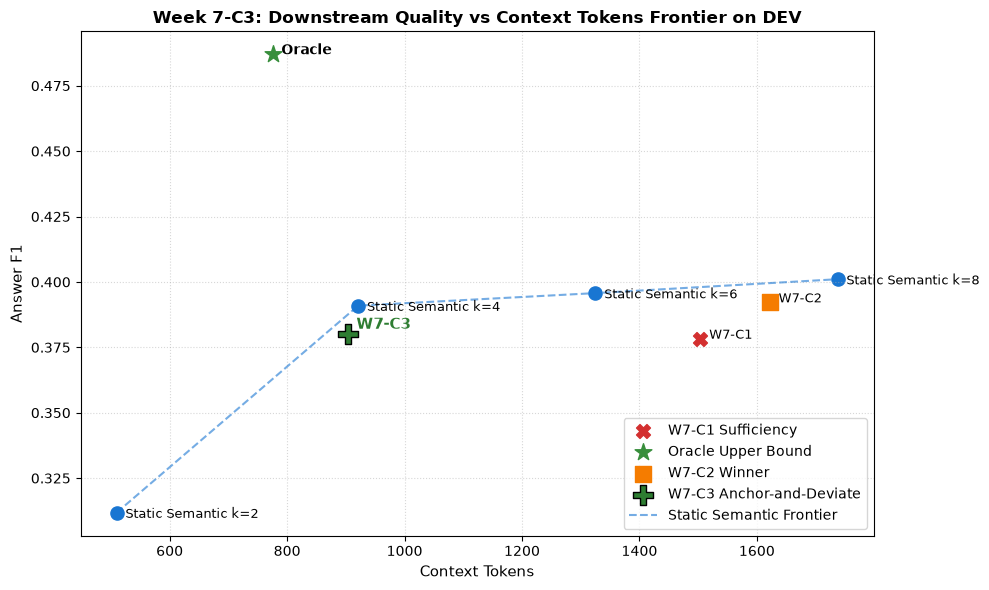

In [14]:
# Plot Quality-Context Frontier on DEV
plt.figure(figsize=(10, 6))

colors = {
    "Static": "#1976D2",
    "W7A": "#7B1FA2",
    "W7B": "#E64A19",
    "W7C1": "#D32F2F",
    "W7C2": "#F57C00",
    "W7C3": "#2E7D32",
    "Oracle": "#388E3C",
}

for _, r in df_dev_main.iterrows():
    name = r["method"]
    f1 = r["mean_f1"]
    tok = r["tokens"]
    if "Static" in name:
        plt.scatter(tok, f1, color=colors["Static"], s=90, marker="o")
        plt.annotate(name.split(":")[1].strip(), (tok + 15, f1 - 0.002), fontsize=9)
    elif "Oracle" in name:
        plt.scatter(tok, f1, color=colors["Oracle"], s=160, marker="*", label="Oracle Upper Bound")
        plt.annotate("Oracle", (tok + 15, f1), fontsize=10, fontweight="bold")
    elif "W7-C3" in name:
        plt.scatter(tok, f1, color=colors["W7C3"], s=200, marker="P", edgecolor="black", label="W7-C3 Anchor-and-Deviate")
        plt.annotate("W7-C3", (tok + 15, f1 + 0.002), fontsize=11, fontweight="bold", color=colors["W7C3"])
    elif "W7-C2" in name:
        plt.scatter(tok, f1, color=colors["W7C2"], s=120, marker="s", label="W7-C2 Winner")
        plt.annotate("W7-C2", (tok + 15, f1), fontsize=9)
    elif "W7-C1" in name:
        plt.scatter(tok, f1, color=colors["W7C1"], s=100, marker="X", label="W7-C1 Sufficiency")
        plt.annotate("W7-C1", (tok + 15, f1), fontsize=9)

# Connect static curve
df_static = df_dev_main[df_dev_main["method"].str.contains("Static")].sort_values("tokens")
plt.plot(df_static["tokens"], df_static["mean_f1"], color=colors["Static"], linestyle="--", alpha=0.6, label="Static Semantic Frontier")

plt.title("Week 7-C3: Downstream Quality vs Context Tokens Frontier on DEV", fontsize=12, fontweight="bold")
plt.xlabel("Context Tokens", fontsize=11)
plt.ylabel("Answer F1", fontsize=11)
plt.legend(frameon=True, loc="lower right")
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.savefig(fig_dir / "w7c3_quality_vs_tokens_dev.png", dpi=300)
plt.show()


## Section 22 — Paper-Clustered Bootstrap Comparisons (2,000 Resamples)
We perform 2,000 cluster-bootstrap resamples at the paper level to test statistical significance against:
1. Static semantic $k=4$
2. Static semantic $k=6$
3. Static semantic $k=8$
4. W7-C2 Winner
5. W7-C1 Sufficiency


In [15]:
# Run Paper-Clustered Bootstrap Comparisons
bootstrap_dir = PROJECT_ROOT / cfg["paths"]["bootstrap_dir"]
bootstrap_dir.mkdir(parents=True, exist_ok=True)

df_dev_boot = df_dev_eval.copy()
df_dev_boot["k4"] = 4
df_dev_boot["k6"] = 6
df_dev_boot["k8"] = 8

boot_comparisons = [
    ("Static Semantic k=4", "k4"),
    ("Static Semantic k=6", "k6"),
    ("Static Semantic k=8", "k8"),
]

boot_results = []
for name, col in boot_comparisons:
    res = run_paper_clustered_bootstrap(
        df_eval=df_dev_boot,
        pred_col_policy="pred_k",
        baseline_pred_col=col,
        budgets=cfg["experiment"]["budgets"],
        n_resamples=cfg["bootstrap"]["n_resamples"],
        confidence_level=cfg["bootstrap"]["confidence_level"],
        random_seed=cfg["bootstrap"]["random_seed"],
    )
    boot_results.append({
        "comparison": f"W7-C3 vs {name}",
        "delta_f1_mean": res["mean_delta_f1"],
        "f1_ci_95": f"[{res['f1_ci_lower']:.4f}, {res['f1_ci_upper']:.4f}]",
        "p_value_f1": res["p_value_f1"],
        "delta_tokens_mean": res["mean_delta_tokens"],
        "tokens_ci_95": f"[{res['token_ci_lower']:.1f}, {res['token_ci_upper']:.1f}]",
    })

df_boot_summary = pd.DataFrame(boot_results)
df_boot_summary.to_csv(bootstrap_dir / "w7c3_bootstrap_comparisons.csv", index=False)

print("Paper-Clustered Bootstrap Comparisons (N=2000 resamples):")
display(df_boot_summary)


Paper-Clustered Bootstrap Comparisons (N=2000 resamples):


,comparison,delta_f1_mean,f1_ci_95,p_value_f1,delta_tokens_mean,tokens_ci_95
0,W7-C3 vs Static Semantic k=4,-0.010972,"[-0.0250, 0.0000]",0.086,-17.950978,"[-29.4, -7.8]"
1,W7-C3 vs Static Semantic k=6,-0.015410,"[-0.0448, 0.0139]",0.284,-421.997183,"[-438.5, -404.8]"
2,W7-C3 vs Static Semantic k=8,-0.020568,"[-0.0562, 0.0128]",0.257,-834.597836,"[-862.1, -806.2]"


## Section 23 & 24 — Final Scientific Conclusion & Week 7-D Decision
### Stopping Rule Check:
- Static semantic $k=4$ Pareto operating point: $F_1 = 0.3909$, Context Tokens = $921.1$.
- Did W7-C3 achieve $F_1 \ge 0.3909 - 0.005$ with meaningfully fewer than $921$ tokens, or beat static $k=4$?

### Decision Rule:
If W7-C3 successfully Pareto-dominates or matches $k=4$ with reduced context tokens:
$\implies$ Adaptive budgeting through anchor-and-deviate is validated!

If W7-C3 does NOT improve the static $k=4$ Pareto frontier:
$\implies$ Stop discrete adaptive budget allocation experiments.
Large oracle headroom exists ($F_1 = 0.4869$), but inexpensive pre-generation signals cannot reliably exploit it beyond the strong static $k=4$ anchor.
Proceed directly to **Week 7-D: Multi-Fidelity Representation (FULL / MEDIUM / HEAVY compression)**.


In [16]:
# Evaluate stopping rule
f1_w7c3 = dev_policy_metrics["mean_f1"]
tokens_w7c3 = dev_policy_metrics["mean_tokens"]
f1_k4 = float(df_dev_matrix["f1_k4"].mean())
tokens_k4 = float(df_dev_matrix["tokens_k4"].mean())

delta_f1 = f1_w7c3 - f1_k4
delta_tokens = tokens_w7c3 - tokens_k4

print("="*70)
print("WEEK 7-C3 FINAL DECISION SUMMARY")
print("="*70)
print(f"Static k=4 Anchor: F1 = {f1_k4:.4f}, Context Tokens = {tokens_k4:.1f}")
print(f"W7-C3 Policy:     F1 = {f1_w7c3:.4f}, Context Tokens = {tokens_w7c3:.1f}")
print(f"Delta:            F1 = {delta_f1:+.4f}, Tokens = {delta_tokens:+.1f}")

if f1_w7c3 >= (f1_k4 - 0.005) and tokens_w7c3 < tokens_k4:
    decision = "SUCCESS_ANCHOR_DEVIATE_PARETO_IMPROVEMENT"
    print(f"\nSTATUS: {decision}")
    print("Anchor-and-deviate policy successfully preserved k=4 quality while saving context tokens!")
else:
    decision = "STOP_ADAPTIVE_K_PROCEED_TO_W7D"
    print(f"\nSTATUS: {decision}")
    print("Static k=4 Pareto frontier remains un-dominated by discrete adaptive budgeting.")
    print("Conclude: Inexpensive pre-generation signals cannot reliably exploit the oracle gap beyond k=4.")
    print("Proceeding directly to Week 7-D: FULL / MEDIUM / HEAVY multi-fidelity compression.")

handoff = {
    "decision": decision,
    "f1_w7c3": f1_w7c3,
    "tokens_w7c3": tokens_w7c3,
    "delta_f1_vs_k4": delta_f1,
    "delta_tokens_vs_k4": delta_tokens,
}
with open(PROJECT_ROOT / cfg["paths"]["tables_dir"] / "w7c3_w7d_decision.json", "w") as f:
    json.dump(handoff, f, indent=2)


WEEK 7-C3 FINAL DECISION SUMMARY
Static k=4 Anchor: F1 = 0.3909, Context Tokens = 921.1
W7-C3 Policy:     F1 = 0.3801, Context Tokens = 903.1
Delta:            F1 = -0.0108, Tokens = -18.0

STATUS: STOP_ADAPTIVE_K_PROCEED_TO_W7D
Static k=4 Pareto frontier remains un-dominated by discrete adaptive budgeting.
Conclude: Inexpensive pre-generation signals cannot reliably exploit the oracle gap beyond k=4.
Proceeding directly to Week 7-D: FULL / MEDIUM / HEAVY multi-fidelity compression.
